# 14-3. 금 가격 선정 모델 vs TVP 모델 비교

`14-2`에서 고른 금 가격 선정 모델(GARCH·(1,1)·로그·리샘플링)과 앱의 TVP 금 가격 모델을 **같은 origin, 같은 지표**로 비교한다.

- **TVP 모델**: 금 가격 YoY(로그 차이)를 변수 6개로 설명하는 시변계수 회귀. 2016Q1부터 학습하고 앱의 `gold_price_model.py`와 같은 방식으로 적합한다. 앱은 점예측만 쓰므로, 구간은 예측 표준오차(정규 가정)로 만들어 90% 구간과 CRPS를 계산한다.
- **비교 기준은 `TVP(예측 X)`**: 12시리즈 선정 모델로 변수를 예측 시점의 데이터만으로 예측해 TVP에 넣는다. 선정 모델과 같은 정보만 쓰므로 공정하다. `TVP(실제 X)`(예측 분기의 변수 실제값을 넣음)는 현실에서 불가능한 상한선이라 참고로만 보인다.
- **비교 origin**: TVP 학습 행이 24개 이상인 origin부터(2022Q1 예측 시작) 데이터 끝까지. 선정 모델은 같은 origin만 평가한다.
- **지표**: 14-2와 같다(h=1~4, 금 가격 표준편차로 정규화, 커버리지 목표 90%).

## 1. 구현

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
from scipy import stats
from arch.univariate import ARX, ConstantMean, GARCH, ZeroMean
from scipy.optimize import minimize
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 차분·역차분·σ 전파
def diff_poly(sp):
    c = np.array([1.0])
    for _ in range(sp.d):
        c = np.convolve(c, [1.0, -1.0])
    for _ in range(sp.D):
        c = np.convolve(c, np.r_[1.0, np.zeros(sp.m - 1), -1.0])
    return c


def difference(y, sp):
    c, y = diff_poly(sp), np.asarray(y, float)
    k = len(c) - 1
    return y.copy() if k == 0 else np.convolve(y, c)[k:len(y)]


def undiff(w_fc, y, sp):
    c = diff_poly(sp)
    hist, out = list(map(float, y)), []
    for wf in w_fc:
        yt = wf - sum(c[i] * hist[-i] for i in range(1, len(c)))
        hist.append(yt)
        out.append(yt)
    return np.array(out)


def level_sigma(lags, ar, sp, innov_var):
    """h단계 수준 예측오차의 표준편차. 평균식 AR 다항식과 차분 다항식을 곱한 다항식으로 충격반응(psi)을 구한다."""
    ar_poly = np.zeros(max(lags) + 1 if len(lags) else 1)
    ar_poly[0] = 1.0
    for l, a in zip(lags, ar):
        ar_poly[l] -= a
    a_full = -np.convolve(ar_poly, diff_poly(sp))[1:]
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(a_full[k - 1] * psi[j - k] for k in range(1, min(j, len(a_full)) + 1))
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def lag_list(p, P, m):
    return sorted(set(range(1, p + 1)) | {m * j for j in range(1, P + 1)})


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


# ---------------------------------------------------------------- GARCH 동시
def garch_forecast(train, sp, lags):
    w = difference(train, sp)
    if lags:
        am = ARX(w, lags=lags, constant=sp.const, rescale=False)
    else:
        am = ConstantMean(w, rescale=False) if sp.const else ZeroMean(w, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{l}]"] for l in lags]
    fc = undiff(f.mean.values[-1], train, sp)
    sig = level_sigma(lags, ar, sp, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- SV 동시 (QML + 칼만필터)
def is_ar_stable(lags, ar):
    if not len(lags):
        return True
    mx = max(lags)
    a = np.zeros(mx)
    for l, c in zip(lags, ar):
        a[l - 1] = c
    comp = np.zeros((mx, mx))
    comp[0, :] = a
    if mx > 1:
        comp[1:, :-1] = np.eye(mx - 1)
    return np.max(np.abs(np.linalg.eigvals(comp))) < 0.999


def sv_residuals(w, lags, ar, c):
    mx = max(lags) if len(lags) else 0
    return np.array([w[t] - c - sum(a * w[t - l] for a, l in zip(ar, lags)) for t in range(mx, len(w))])


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def _unpack(params, k, const):
    ar = params[:k]
    c = params[k] if const else 0.0
    j = k + (1 if const else 0)
    return ar, c, MAX_PHI * np.tanh(params[j]), np.exp(params[j + 1]) ** 2


def joint_sv_negloglik(params, w, lags, const):
    ar, c, phi, s2 = _unpack(params, len(lags), const)
    if not is_ar_stable(lags, ar):
        return 1e10
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, sp, lags):
    w = difference(train, sp)
    k = len(lags)
    x0 = [0.0] * k + ([float(np.mean(w))] if sp.const else []) + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(w, lags, sp.const), method="Nelder-Mead", options={"maxiter": 3000})
    ar, c, phi, s2 = _unpack(res.x, k, sp.const)
    if not is_ar_stable(lags, ar) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(w[-max(lags):]) if k else []
    mean_w = []
    for _ in range(H):
        pred = c + sum(a * past[-l] for a, l in zip(ar, lags))
        mean_w.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** j * hf + (phi ** (2 * j) * Pf + s2 * sum(phi ** (2 * i) for i in range(j))) / 2) for j in range(1, H + 1)]
    fc, sig = undiff(mean_w, train, sp), level_sigma(lags, ar, sp, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- 공용 진입점
def forecast(model, train, sp=Spec()):
    """model: 'AR단독' | 'GARCH' | 'SV'. 반환: (예측 4개, σ 4개, 사용한 모델, (p, P)). 적합 실패 시 NaN을 돌려준다(src='실패')."""
    p, P, m = select_structure(train, sp)
    if model == "AR단독":
        fc, sig = ar_forecast(m)
        return fc, sig, "AR단독", (p, P)
    lags = lag_list(p, P, sp.m)
    try:
        fc, sig = (garch_forecast if model == "GARCH" else sv_forecast)(train, sp, lags)
        return fc, sig, model, (p, P)
    except Exception:
        nan = np.full(H, np.nan)
        return nan, nan, "실패", (p, P)


## 2. 데이터와 TVP 모델 재현

In [2]:
import properscoring as ps
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

XC = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
STD_XC = ["X1_l1", "X2", "X3_l1", "X4_z", "X5_l1", "X6_l1"]
TRAIN_START, N_ENS, SCALE = "2016Q1", 500, 100.0
x_raw = pd.read_csv("../../data/gold/gold_major_variables.csv", encoding="utf-8-sig", float_precision="round_trip").dropna(subset=["quarter"])
pr = pd.read_csv("../../data/gold/gold_price.csv", encoding="utf-8-sig", float_precision="round_trip")
pr.columns = ["quarter", "gold", "gold_pred"]
df = x_raw.merge(pr.dropna(subset=["quarter"]), on="quarter", how="outer")
df["qdate"] = pd.PeriodIndex(df["quarter"], freq="Q").to_timestamp()
df = df.sort_values("qdate").reset_index(drop=True)
df["yoy_log_gold"] = np.log(df["gold"]) - np.log(df["gold"]).shift(4)
N, SD, Q = len(df), df["gold"].std(ddof=0), df["quarter"].values      # SD: 14-2의 정규화 단위(금 가격 표준편차)
d_all = df[["quarter", "qdate", "yoy_log_gold", *XC]].dropna()
d_all = d_all[d_all["qdate"] >= pd.Period(TRAIN_START, freq="Q").to_timestamp()].reset_index(drop=True)
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)
print(f"금 가격 {N}개 ({Q[0]} ~ {Q[-1]}), 정규화 단위 SD = {SD:.1f}")
print(f"TVP가 쓸 수 있는 학습 행: {d_all['quarter'].iloc[0]} ~ {d_all['quarter'].iloc[-1]} ({len(d_all)}개)")

금 가격 64개 (2010Q1 ~ 2025Q4), 정규화 단위 SD = 579.1
TVP가 쓸 수 있는 학습 행: 2016Q1 ~ 2025Q4 (40개)


In [3]:
def fit_tvp(o):
    """앞 o개 분기(현재 origin 이전)까지의 데이터로 TVP 파라미터를 학습한다. 앱의 _fit_train_tvp와 같다."""
    train = d_all[d_all["qdate"] <= df["qdate"][o - 1]].copy()
    mu_b4, sd_b4 = train["X4"].mean(), train["X4"].std(ddof=0) or 1.0
    train["X4_z"] = (train["X4"] - mu_b4) / sd_b4
    mu, sd = train[STD_XC].mean(), train[STD_XC].std(ddof=0).replace(0, 1.0)
    ts = train.copy()
    ts[STD_XC] = (ts[STD_XC] - mu) / sd
    mod = sm.tsa.SARIMAX(endog=ts["yoy_log_gold"].to_numpy(float), exog=np.column_stack([np.ones(len(ts)), ts[STD_XC].to_numpy(float)]),
                         order=(0, 0, 0), trend="n", time_varying_regression=True, mle_regression=False)
    try:
        res = mod.fit(disp=False, maxiter=3000)
    except Exception:
        res = mod.fit(disp=False, maxiter=6000, method="powell")
    return dict(params=np.asarray(res.params), train=train, mu=mu, sd=sd, mu_b4=mu_b4, sd_b4=sd_b4)


def tvp_predict(fit, xfut):
    """예측 분기들의 X(xfut)를 넣어 yoy_log_gold의 다단계 예측 평균과 표준오차를 돌려준다(dynamic=True)."""
    cols = ["yoy_log_gold", *XC, "X4_z"]
    fr = xfut[XC].astype(float).copy().reset_index(drop=True)
    fr["yoy_log_gold"] = np.nan
    fr["X4_z"] = (fr["X4"] - fit["mu_b4"]) / fit["sd_b4"]
    full = pd.concat([fit["train"][cols], fr[cols]], ignore_index=True)
    full[STD_XC] = (full[STD_XC] - fit["mu"]) / fit["sd"]
    mod = sm.tsa.SARIMAX(endog=full["yoy_log_gold"].to_numpy(float), exog=np.column_stack([np.ones(len(full)), full[STD_XC].to_numpy(float)]),
                         order=(0, 0, 0), trend="n", time_varying_regression=True, mle_regression=False)
    p = mod.filter(fit["params"]).get_prediction(start=len(fit["train"]), end=len(full) - 1, dynamic=True)
    return np.asarray(p.predicted_mean), np.asarray(p.se_mean)

앱의 `predict_final_gold_prices`와 같은 값이 나오는지 확인한다. 5분기 이후는 예측 가격을 이어 쓰는 앱의 방식을 따른다. `gold_price.csv`의 '예측가' 열은 참고로 같이 둔다.

In [4]:
# 앱의 predict_final_gold_prices와 같은 값이 나오는지 확인한다(2016Q1~2023Q4 학습, 2024Q1~2025Q4 8분기 예측, 실제 X 사용)
import sys
sys.path.insert(0, "../..")
import gold_price_model as app
fit56 = fit_tvp(56)
mu8, se8 = tvp_predict(fit56, df.loc[56:63, XC])
price = df["gold"].to_dict()
mine = []
for i in range(8):
    price[56 + i] = price[56 + i - 4] * np.exp(mu8[i])             # 앱과 같이 4분기 전 가격(5분기 이후는 예측 가격)에 곱한다
    mine.append(price[56 + i])
qs = [q.replace("Q", "-Q") for q in Q[56:64]]
rv = {c: {q.replace("Q", "-Q"): float(v) for q, v in zip(x_raw["quarter"], x_raw[c])} for c in XC}
app_out = app.predict_final_gold_prices(rv, qs, {})
chk = pd.DataFrame({"분기": Q[56:64], "재현": mine, "앱 함수": [app_out[q] for q in qs], "gold_price.csv 예측가": df["gold_pred"].values[56:64]})
chk["재현-앱 차이"] = chk["재현"] - chk["앱 함수"]
display(chk.round(3).set_index("분기"))

2026-10-22 13:59:11.974 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
2026-10-22 13:59:12.175 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-22 13:59:12.176 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-22 13:59:12.190 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,재현,앱 함수,gold_price.csv 예측가,재현-앱 차이
분기,,,,
2024Q1,2382.456,2382.456,2208.279,0.0
2024Q2,2297.843,2297.843,2112.590,0.0
2024Q3,2289.379,2289.379,2300.985,0.0
2024Q4,2466.655,2466.655,2494.767,0.0
2025Q1,2746.769,2746.769,2680.867,0.0
2025Q2,2731.791,2731.791,3336.867,0.0
2025Q3,2768.233,2768.233,3459.062,0.0
2025Q4,3085.324,3085.324,3722.669,0.0


## 3. TVP 예측 (실제 X / 예측 X)

In [5]:
MIN_TVP = 24      # TVP 학습 행 수의 하한
START = int(np.where(Q == TRAIN_START)[0][0])       # TVP 학습이 시작되는 행 번호(2016Q1)
ORIG = list(range(START + MIN_TVP, N - H + 1))      # TVP 학습 행이 MIN_TVP개 이상인 origin부터 데이터 끝(마지막 4분기를 예측하는 origin)까지
CACHE = "../cache/cache_143_tvp_df.pkl"


def rows_tvp(case, o, mu_h, se_h):
    out = []
    for h in range(1, H + 1):
        base, a = df["gold"][o + h - 5], df["gold"][o + h - 1]       # 4분기 전 가격(h<=4이면 항상 실제값)과 실제값
        mu, se = mu_h[h - 1], se_h[h - 1]
        lo, hi, med = base * np.exp(mu - Z * se), base * np.exp(mu + Z * se), base * np.exp(mu)
        out.append({"모델": case, "origin": o, "h": h, "분기": Q[o + h - 1], "하한": lo, "상한": hi, "중앙": med, "실제": a,
                    "crps": ps.crps_ensemble(a, base * np.exp(mu + se * U)) / SD, "MSE": ((a - med) / SD) ** 2,
                    "적중": float(lo <= a <= hi) * 100, "폭": (hi - lo) / SD})
    return out

`TVP(예측 X)`에 쓸 변수 예측은 각 origin 이전 데이터만 써서 12시리즈 선정 모델로 만든 중앙값 예측이다.

In [6]:
SEL_X = {"X3_l1": ("GARCH", 1, 0, "원"), "X6_l1": ("SV", 1, 0, "원"), "X2": ("AR단독", 0, 0, "원"),
         "X1_l1": ("GARCH", 0, 0, "원"), "X5_l1": ("GARCH", 0, 0, "로그"), "X4": ("GARCH", 0, 0, "원")}   # 12시리즈 선정 모델(모델, d, D, 스케일)
XCACHE = "../cache/cache_143_xfc_df.pkl"


x_def = pd.read_csv("../../data/gold/gold_major_variables.csv", encoding="utf-8-sig").dropna(subset=["quarter"])      # 12시리즈와 같은 파싱(변수 예측용). TVP는 앱과 같은 round_trip 파싱을 쓴다


def x_point(v, o):
    """origin o(금 가격 기준)에서 변수 v의 o ~ o+3분기 점예측. 그 분기 이전 데이터만 쓰고, 선정 모델의 중앙값 예측을 쓴다."""
    model, d, D, sc = SEL_X[v]
    s = x_def[["quarter", v]].dropna().reset_index(drop=True)
    ov = int((s["quarter"] < Q[o]).sum())
    assert s["quarter"][ov - 1] == str(pd.Period(Q[o], freq="Q") - 1), (v, o)        # 훈련 마지막 분기가 예측 직전 분기여야 한다
    y0 = s[v].values.astype(float)
    C = 100 / y0[:ov].std()                                       # 단위 상수: 훈련 구간 표준편차(미래 정보 없음)
    ser = SCALE * np.log(y0 * C) if sc == "로그" else y0 * C
    fc, sig, src, _ = forecast(model, ser[:ov], Spec(d=d, D=D))
    pt = np.exp(fc / SCALE) if sc == "로그" else fc
    return pt / C, src


if os.path.exists(XCACHE):
    xfc = pd.read_pickle(XCACHE)
else:
    xfc = pd.DataFrame([{"변수": v, "origin": o, "h": h, "예측": p, "src": src} for o in ORIG for v in XC
                        for (pt, src) in [x_point(v, o)] for h, p in enumerate(pt, 1)])
    xfc.to_pickle(XCACHE)
print("변수 점예측:", len(xfc), "행, 적합 실패", int((xfc["src"] == "실패").sum()), "회")

변수 점예측: 312 행, 적합 실패 0 회


In [7]:
if os.path.exists(CACHE):
    tv = pd.read_pickle(CACHE)
else:
    rows = []
    for o in ORIG:
        fit = fit_tvp(o)
        x_act = df.loc[o:o + H - 1, XC]
        x_fc = xfc[xfc["origin"] == o].pivot(index="h", columns="변수", values="예측")[XC]
        rows += rows_tvp("TVP(실제 X)", o, *tvp_predict(fit, x_act))
        rows += rows_tvp("TVP(예측 X)", o, *tvp_predict(fit, x_fc))
    tv = pd.DataFrame(rows)
    tv.to_pickle(CACHE)
print(f"TVP origin {len(ORIG)}개 ({Q[ORIG[0]]} 예측 시작 ~ {Q[ORIG[-1]]} 예측 시작), 행 {len(tv)}")

TVP origin 13개 (2022Q1 예측 시작 ~ 2025Q1 예측 시작), 행 104


## 4. 선정 모델과 비교

In [8]:
c142 = pd.read_pickle("../cache/cache_142_gold_price_df.pkl")
selm = c142[(c142["모델"] == "GARCH") & (c142["d"] == 1) & (c142["D"] == 1) & (c142["스케일"] == "로그") & (c142["구간"] == "리샘플링")]
selm = selm[selm["origin"].isin(ORIG)].assign(모델="선정 모델")
ALL = pd.concat([selm[["모델", "origin", "h", "crps", "MSE", "적중", "폭"]], tv[["모델", "origin", "h", "crps", "MSE", "적중", "폭"]]])
ORDER = ["선정 모델", "TVP(실제 X)", "TVP(예측 X)"]


def summ(a):
    per = a.groupby(["모델", "origin"])[["crps", "MSE", "적중", "폭"]].mean()
    return per.groupby("모델").mean().loc[ORDER].rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})


print(f"비교 origin {len(ORIG)}개 ({Q[ORIG[0]]} ~ {Q[ORIG[-1]]}에서 예측 시작), 모델당 행 {len(selm)}")
T_ALL = summ(ALL)
T_REC = summ(ALL[ALL["origin"] >= 56])
MAIN = ["선정 모델", "TVP(예측 X)"]
print("[공통 origin 전체]  마지막 행은 참고(현실에서 불가능한 상한선)")
display(T_ALL.loc[MAIN + ["TVP(실제 X)"]].round(4))
print("[최근 origin 56~60 (2024Q1~ 예측 시작, 앱의 기존 평가 구간과 겹침)]")
display(T_REC.loc[MAIN + ["TVP(실제 X)"]].round(4))

비교 origin 13개 (2022Q1 ~ 2025Q1에서 예측 시작), 모델당 행 52
[공통 origin 전체]  마지막 행은 참고(현실에서 불가능한 상한선)


,CRPS,MSE,커버리지(%),폭
모델,,,,
선정 모델,0.2692,0.2636,84.6154,1.2573
TVP(예측 X),0.2366,0.1933,76.9231,0.8414
TVP(실제 X),0.2995,0.2398,78.8462,1.5272


[최근 origin 56~60 (2024Q1~ 예측 시작, 앱의 기존 평가 구간과 겹침)]


,CRPS,MSE,커버리지(%),폭
모델,,,,
선정 모델,0.4110,0.5240,65.0,1.4209
TVP(예측 X),0.4398,0.4419,50.0,0.9287
TVP(실제 X),0.3462,0.3009,65.0,1.0886


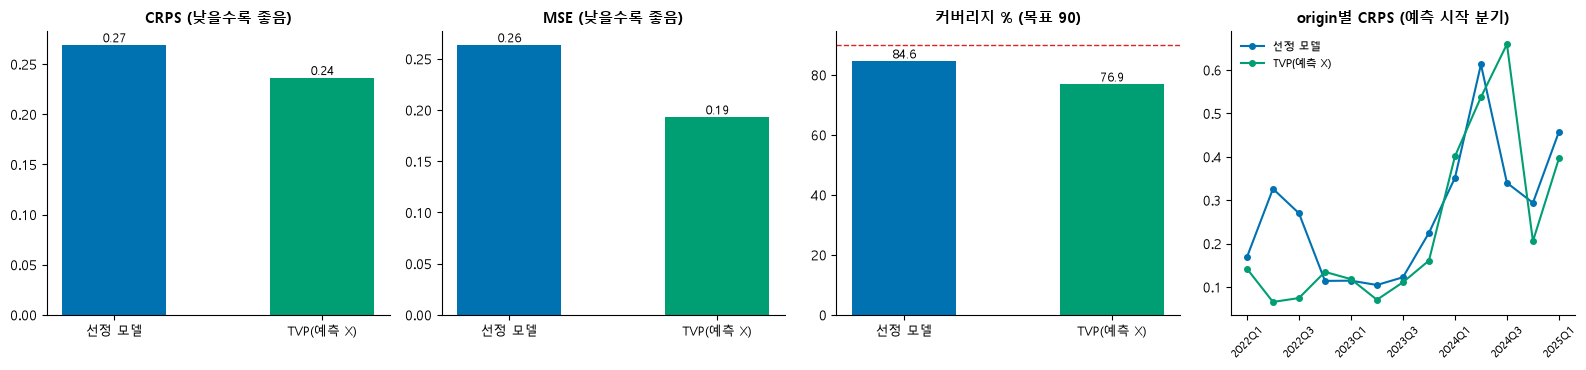

예측 시점(h)별 CRPS


h,1,2,3,4
모델,,,,
선정 모델,0.1044,0.2077,0.3050,0.4597
TVP(예측 X),0.1234,0.1874,0.2597,0.3757
TVP(실제 X),0.1906,0.2847,0.3423,0.3804


In [9]:
MC = {"선정 모델": "#0072B2", "TVP(실제 X)": "#E8590C", "TVP(예측 X)": "#009E73"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c, ttl in zip(axes[:3], ["CRPS", "MSE", "커버리지(%)"], ["CRPS (낮을수록 좋음)", "MSE (낮을수록 좋음)", "커버리지 % (목표 90)"]):
    v = T_ALL.loc[MAIN, c].values
    ax.bar(range(2), v, color=[MC[m] for m in MAIN], width=0.5)
    for k, x in enumerate(v):
        ax.text(k, x, f"{x:.2f}" if c != "커버리지(%)" else f"{x:.1f}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지(%)":
        ax.axhline(90, color="#D62728", linestyle="--", linewidth=1)
    ax.set_xticks(range(2))
    ax.set_xticklabels(["선정 모델", "TVP(예측 X)"], fontsize=9)
    ax.set_title(ttl, fontsize=10.5, fontweight="bold")
per_o = ALL.groupby(["모델", "origin"])["crps"].mean().unstack(0)[ORDER]
for m in MAIN:
    axes[3].plot(per_o.index, per_o[m], color=MC[m], marker="o", markersize=4, label=m)
axes[3].set_xticks(per_o.index[::2])
axes[3].set_xticklabels([Q[o] for o in per_o.index[::2]], rotation=45, fontsize=8)
axes[3].set_title("origin별 CRPS (예측 시작 분기)", fontsize=10.5, fontweight="bold")
axes[3].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()
print("예측 시점(h)별 CRPS")
display(ALL.groupby(["모델", "h"])["crps"].mean().unstack().loc[MAIN + ["TVP(실제 X)"]].round(4))

## 5. origin 구간 비교

TVP(예측 X)가 선정 모델보다 가장 유리했던/불리했던 origin과 처음·마지막 origin을 골라 구간을 겹쳐 본다. TVP의 구간은 변수 예측의 오차를 반영하지 않아 좁게 나올 수 있다.

In [10]:
# 선정 모델의 구간(13시리즈와 같은 계산)을 만들고, 비교할 origin을 고른다
SEL = {"gold_price": ("GARCH", 1, 1, "로그", "리샘플링")}
SEED = 42
SCALE, N_ENS, MIN_TRAIN, INITIAL_CALIB, N_HIST = 100.0, 500, 20, 15, 8
TAUS = [0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]
raw = df[["quarter", "gold"]].rename(columns={"gold": "gold_price"})
def next_quarter(lab):
    y_, q_ = int(lab[:4]), int(lab[5])
    return f"{y_ + (q_ == 4)}Q{q_ % 4 + 1}"


def run_variable(v):
    """변수 v의 선정 모델로 모든 채점 origin의 예측구간(90%)과 7분위를 계산한다. 12시리즈와 같은 방식, 같은 시드."""
    model, d, D, sc, iv = SEL[v]
    sp, logm, std = Spec(d=d, D=D), sc == "로그", model != "AR단독"
    s_ = raw[["quarter", v]].dropna().reset_index(drop=True)
    y0, q = s_[v].values.astype(float), s_["quarter"].values
    vals = y0
    var_std = y0.std()                                                          # 점수 정규화 단위(원래 단위)


    def ser(o):                                                                 # origin o의 단위 상수(훈련 구간 표준편차 기준)와 모델 입력 계열
        C = 100 / vals[:o].std()
        return C, (SCALE * np.log(vals * C) if logm else vals * C)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logm else (lambda x: np.asarray(x))
    qfull = list(q)
    while len(qfull) < len(vals) + H:
        qfull.append(next_quarter(qfull[-1]))                                   # 데이터 이후의 예측 분기 이름
    rng = np.random.default_rng(SEED)
    errs = {h: [] for h in range(1, H + 1)}
    rows = []
    n = len(vals)
    for oi, o in enumerate(range(MIN_TRAIN, n + 1)):                              # 데이터 끝까지의 모든 origin(마지막 4개는 실제값이 일부 또는 전부 없음)
        C, series = ser(o)
        fc, sig, src, _ = forecast(model, series[:o], sp)
        if oi >= INITIAL_CALIB:                                                  # 구간을 만드는 origin(채점은 실제값이 있는 분기만)
            for h in range(1, H + 1):
                s_h = max(sig[h - 1], 1e-6)
                if iv == "자체":
                    lo, hi = tf(fc[h - 1] - Z * s_h), tf(fc[h - 1] + Z * s_h)
                    qs = tf(fc[h - 1] + s_h * stats.norm.ppf(TAUS))
                else:
                    pool = np.array([e for o2, e in errs[h] if o2 + h <= o]) * (C if (not std and not logm) else 1)      # 정답이 확정된 오차만
                    samples = fc[h - 1] + (s_h if std else 1.0) * rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
                    lo, hi = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                    qs = tf(np.quantile(samples, TAUS))
                lo, hi, qs = lo / C, hi / C, np.asarray(qs) / C                       # 원래 단위로 되돌린다
                known = o + h - 1 < n                                                 # 실제값이 있는 분기인가
                a = vals[o + h - 1] if known else np.nan
                rows.append({"origin": o, "h": h, "분기": qfull[o + h - 1], "하한": float(lo), "상한": float(hi), "실제": a, "적중": float(lo <= a <= hi) if known else np.nan,
                             "폭_정규화": float((hi - lo) / var_std), **{f"q{int(round(tt * 100))}": float(x) for tt, x in zip(TAUS, qs)}})
        for h in range(1, H + 1):
            if o + h - 1 < n:                                                       # 정답이 있는 오차만 풀에 쌓는다
                e = series[o + h - 1] - fc[h - 1]
                errs[h].append((o, e / max(sig[h - 1], 1e-6) if std else e / (1 if logm else C)))
    return pd.DataFrame(rows), dict(q=np.array(qfull), y=y0)


res_g, info_g = run_variable("gold_price")
chk_ = res_g[res_g["origin"].isin(ORIG)].merge(selm.assign(origin=selm["origin"])[["origin", "h", "적중", "폭"]], on=["origin", "h"], suffixes=("", "_c"))
print("12시리즈 계산과 일치:", "적중", bool((chk_["적중"] * 100 == chk_["적중_c"]).all()), ", 폭 최대 차이", float((chk_["폭_정규화"] - chk_["폭"]).abs().max()))

12시리즈 계산과 일치: 적중 True , 폭 최대 차이 0.0


선택한 origin (예측 시작 분기, TVP(예측 X) - 선정 모델 CRPS 차이):
  origin 49 (2022Q2 ~ 2023Q1): -0.261 <- TVP가 가장 유리
  origin 58 (2024Q3 ~ 2025Q2): +0.319 <- TVP가 가장 불리
  origin 48 (2022Q1 ~ 2022Q4): -0.027 
  origin 60 (2025Q1 ~ 2025Q4): -0.061 


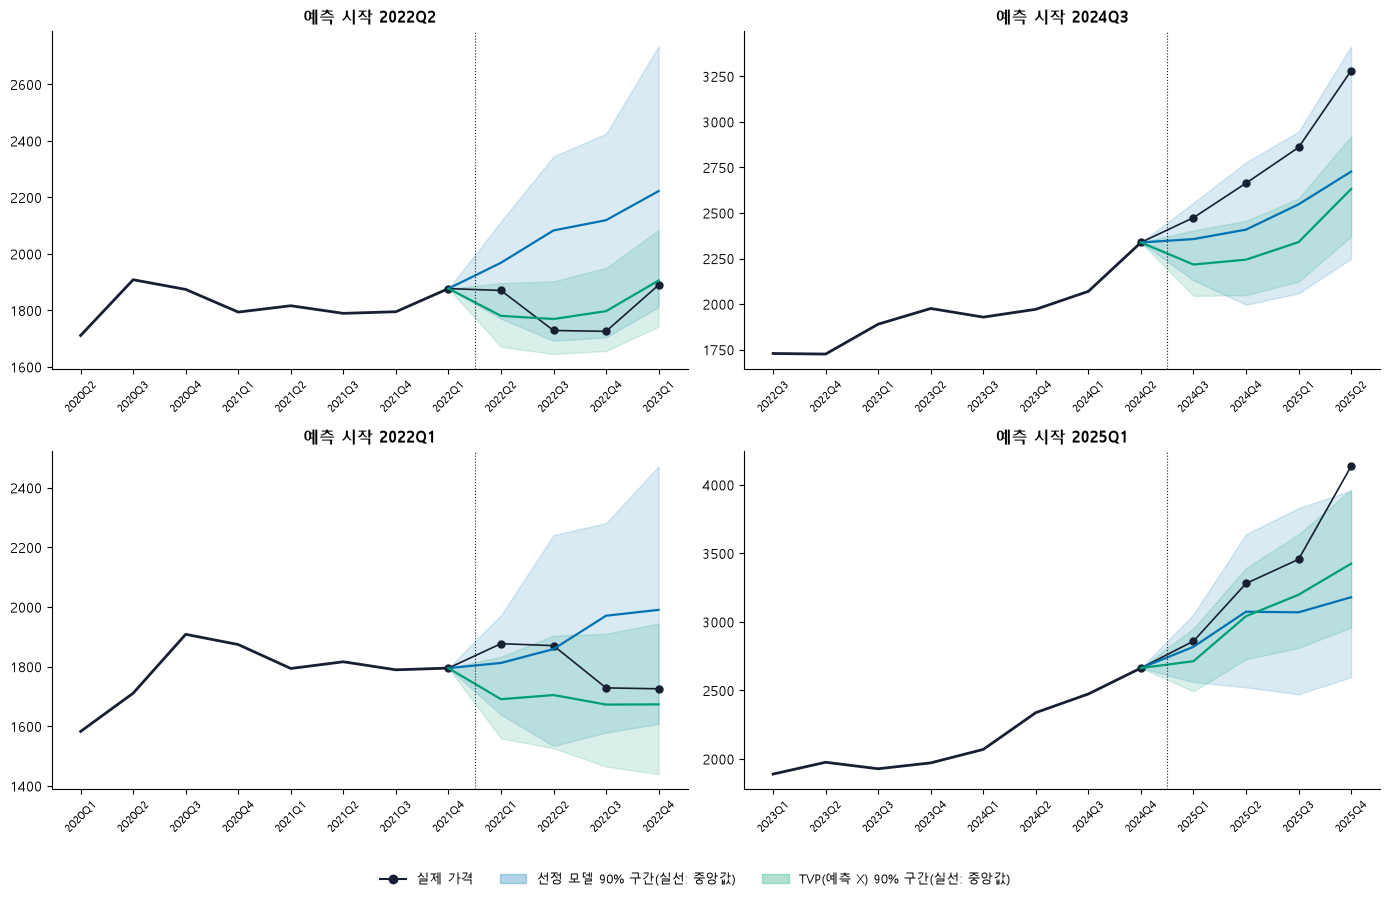

In [11]:
gap = (per_o["TVP(예측 X)"] - per_o["선정 모델"])
PICKED = [gap.idxmin(), gap.idxmax(), ORIG[0], ORIG[-1]]
PICKED = list(dict.fromkeys(PICKED))
print("선택한 origin (예측 시작 분기, TVP(예측 X) - 선정 모델 CRPS 차이):")
for o in PICKED:
    print(f"  origin {o} ({Q[o]} ~ {Q[o + H - 1]}): {gap[o]:+.3f}", "<- TVP가 가장 유리" if o == gap.idxmin() else ("<- TVP가 가장 불리" if o == gap.idxmax() else ""))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, o in zip(axes.ravel(), PICKED):
    ks, fk = np.arange(o - N_HIST, o), np.arange(o, o + H)
    ax.plot(ks, df["gold"].values[ks], color="#172033", linewidth=2)
    ax.plot(np.r_[o - 1, fk], np.r_[df["gold"][o - 1], df["gold"].values[fk]], color="#172033", linewidth=1.2, marker="o", markersize=5)
    s_ = res_g[res_g["origin"] == o].sort_values("h")
    ax.fill_between(np.r_[o - 1, fk], np.r_[df["gold"][o - 1], s_["하한"]], np.r_[df["gold"][o - 1], s_["상한"]], color=MC["선정 모델"], alpha=0.15)
    ax.plot(np.r_[o - 1, fk], np.r_[df["gold"][o - 1], s_["q50"]], color=MC["선정 모델"], linewidth=1.6)
    t_ = tv[(tv["모델"] == "TVP(예측 X)") & (tv["origin"] == o)].sort_values("h")
    ax.fill_between(np.r_[o - 1, fk], np.r_[df["gold"][o - 1], t_["하한"]], np.r_[df["gold"][o - 1], t_["상한"]], color=MC["TVP(예측 X)"], alpha=0.15)
    ax.plot(np.r_[o - 1, fk], np.r_[df["gold"][o - 1], t_["중앙"]], color=MC["TVP(예측 X)"], linewidth=1.6)
    ax.axvline(o - 0.5, color="#172033", linestyle=":", linewidth=0.8)
    ax.set_xticks(np.arange(o - N_HIST, o + H))
    ax.set_xticklabels(Q[o - N_HIST:o + H], rotation=45, fontsize=8)
    ax.set_title(f"예측 시작 {Q[o]}", fontsize=11.5, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Line2D([0], [0], color="#172033", marker="o", label="실제 가격"), Patch(color=MC["선정 모델"], alpha=0.3, label="선정 모델 90% 구간(실선: 중앙값)"),
                    Patch(color=MC["TVP(예측 X)"], alpha=0.3, label="TVP(예측 X) 90% 구간(실선: 중앙값)")], loc="lower center", ncol=3, frameon=False, fontsize=9.5)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 6. origin별 적중과 빗나감

같은 origin·h에서 두 모델의 90% 구간이 실제 가격을 포함했는지 비교한다.

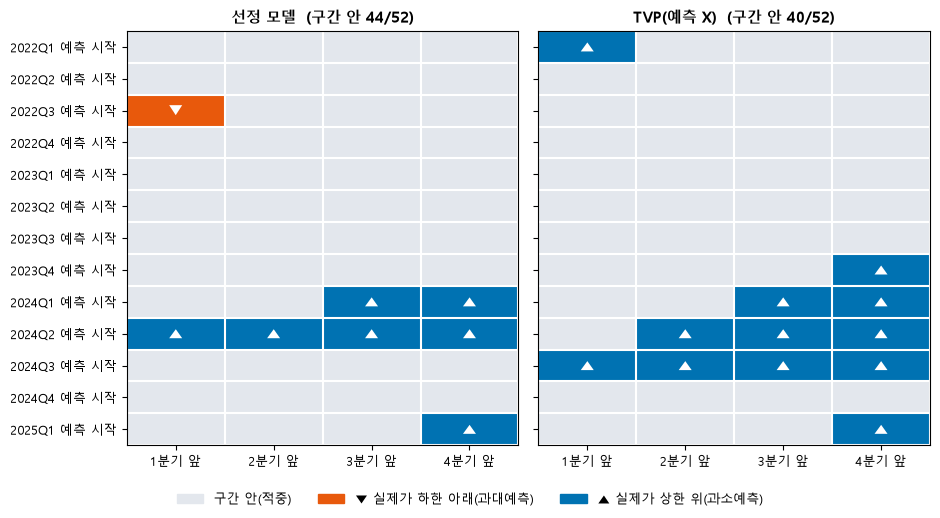

예측 시작,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1
선정 모델 적중(4개 중),4,4,3,4,4,4,4,4,2,0,4,4,3
TVP(예측 X) 적중(4개 중),3,4,4,4,4,4,4,3,2,1,0,4,3


52개 예측(origin x h) 중: {'둘 다 적중': 38, '선정 모델만 적중': 6, 'TVP만 적중': 2, '둘 다 빗나감': 6}
빗나간 방향  선정 모델: 하한 아래 1 / 상한 위 7   TVP(예측 X): 하한 아래 0 / 상한 위 12


In [12]:
def judge(lo, hi, a):
    return np.where(a < lo, -1, np.where(a > hi, 1, 0))          # -1: 실제가 하한 아래, 0: 구간 안, 1: 실제가 상한 위


S = res_g[res_g["origin"].isin(ORIG)].sort_values(["origin", "h"])
T = tv[tv["모델"] == "TVP(예측 X)"].sort_values(["origin", "h"])
js = judge(S["하한"].values, S["상한"].values, S["실제"].values).reshape(len(ORIG), H)
jt = judge(T["하한"].values, T["상한"].values, T["실제"].values).reshape(len(ORIG), H)
from matplotlib.colors import ListedColormap
cm = ListedColormap(["#E8590C", "#E3E7ED", "#0072B2"])
fig, axes = plt.subplots(1, 2, figsize=(9.5, 5.2), sharey=True)
for ax, j, ttl in zip(axes, [js, jt], ["선정 모델", "TVP(예측 X)"]):
    ax.imshow(j, cmap=cm, vmin=-1, vmax=1, aspect="auto")
    for (r_, c_), v in np.ndenumerate(j):
        ax.text(c_, r_, {-1: "▼", 0: "", 1: "▲"}[v], ha="center", va="center", color="white", fontsize=11)
    ax.set_xticks(range(H))
    ax.set_xticklabels([f"{h}분기 앞" for h in range(1, H + 1)], fontsize=9)
    ax.set_title(f"{ttl}  (구간 안 {int((j == 0).sum())}/{j.size})", fontsize=11, fontweight="bold")
    for k in range(len(ORIG) + 1):
        ax.axhline(k - 0.5, color="white", linewidth=1.5)
    for k in range(H + 1):
        ax.axvline(k - 0.5, color="white", linewidth=1.5)
axes[0].set_yticks(range(len(ORIG)))
axes[0].set_yticklabels([f"{Q[o]} 예측 시작" for o in ORIG], fontsize=9)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#E3E7ED", label="구간 안(적중)"), Patch(color="#E8590C", label="▼ 실제가 하한 아래(과대예측)"), Patch(color="#0072B2", label="▲ 실제가 상한 위(과소예측)")],
           loc="lower center", ncol=3, frameon=False, fontsize=9.5)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

hs, ht = (js == 0), (jt == 0)
tab = pd.DataFrame({"선정 모델 적중(4개 중)": hs.sum(1), "TVP(예측 X) 적중(4개 중)": ht.sum(1)}, index=[Q[o] for o in ORIG])
tab.index.name = "예측 시작"
display(tab.T)
both = pd.Series({"둘 다 적중": int((hs & ht).sum()), "선정 모델만 적중": int((hs & ~ht).sum()), "TVP만 적중": int((~hs & ht).sum()), "둘 다 빗나감": int((~hs & ~ht).sum())})
print("52개 예측(origin x h) 중:", both.to_dict())
print("빗나간 방향  선정 모델: 하한 아래", int((js == -1).sum()), "/ 상한 위", int((js == 1).sum()), "  TVP(예측 X): 하한 아래", int((jt == -1).sum()), "/ 상한 위", int((jt == 1).sum()))

## 7. 변동성 큰 origin vs 전체

origin 직전 8분기 가격 변화의 표준편차가 비교 origin 13개의 중앙값보다 큰 origin을 변동성 큰 origin으로 보고, 두 모델의 지표를 나눠 본다(12시리즈의 변동성 민감도와 같은 정의).

변동성 큰 origin 6개: 2022Q1, 2024Q1, 2024Q2, 2024Q3, 2024Q4, 2025Q1 (기준 중앙값 87.3)


CRPS     MSE  커버리지(%)    구간 폭
구분                모델                                        
전체 (13개)          선정 모델      0.2692  0.2636  84.6154  1.2573
                  TVP(예측 X)  0.2366  0.1933  76.9231  0.8414
변동성 큰 origin (6개) 선정 모델      0.3706  0.4519  70.8333  1.3716
                  TVP(예측 X)  0.3902  0.3767  54.1667  0.8892
나머지 origin (7개)   선정 모델      0.1822  0.1022  96.4286  1.1593
                  TVP(예측 X)  0.1049  0.0360  96.4286  0.8004

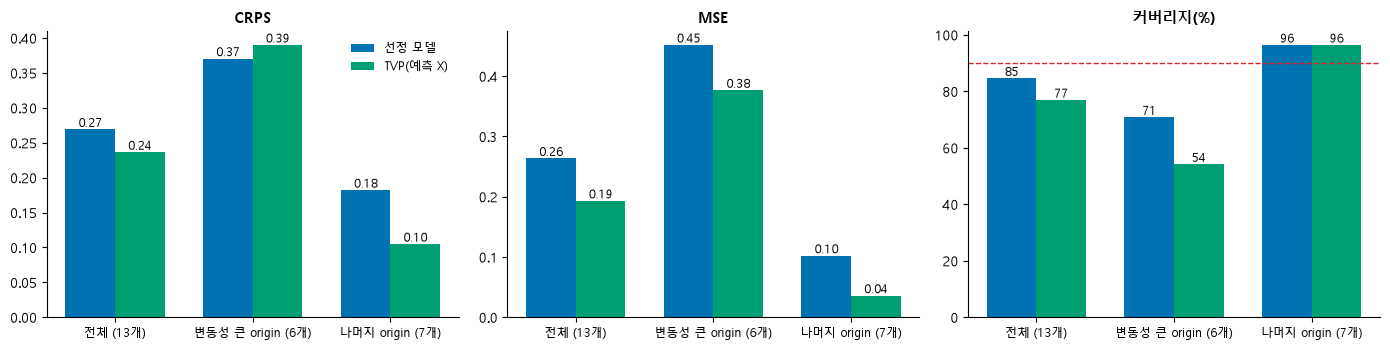

In [13]:
yv = df["gold"].values.astype(float)
vol = pd.Series({o: np.std(np.diff(yv[:o])[-8:]) for o in ORIG})           # origin 직전 8분기 가격 변화의 표준편차
high = vol > vol.median()                                                  # 비교 origin 13개의 중앙값보다 크면 변동성 큰 origin
print(f"변동성 큰 origin {int(high.sum())}개:", ", ".join(Q[o] for o in vol.index[high]), f"(기준 중앙값 {vol.median():.1f})")
per = ALL[ALL["모델"].isin(MAIN)].groupby(["모델", "origin"])[["crps", "MSE", "적중", "폭"]].mean()
rows = []
for nm, mask in [("전체", pd.Series(True, index=vol.index)), ("변동성 큰 origin", high), ("나머지 origin", ~high)]:
    for m in MAIN:
        r_ = per.loc[m].loc[vol.index[mask]].mean()
        rows.append({"구분": f"{nm} ({int(mask.sum())}개)", "모델": m, "CRPS": r_["crps"], "MSE": r_["MSE"], "커버리지(%)": r_["적중"], "구간 폭": r_["폭"]})
VT = pd.DataFrame(rows).set_index(["구분", "모델"])
display(VT.round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
grp = list(dict.fromkeys(VT.index.get_level_values(0)))
for ax, c in zip(axes, ["CRPS", "MSE", "커버리지(%)"]):
    for k, m in enumerate(MAIN):
        v = [VT.loc[(g, m), c] for g in grp]
        ax.bar(np.arange(3) + (k - 0.5) * 0.36, v, 0.36, color=MC[m], label=m)
        for x_, y_ in zip(np.arange(3) + (k - 0.5) * 0.36, v):
            ax.text(x_, y_, f"{y_:.2f}" if c != "커버리지(%)" else f"{y_:.0f}", ha="center", va="bottom", fontsize=8.5)
    if c == "커버리지(%)":
        ax.axhline(90, color="#D62728", linestyle="--", linewidth=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(grp, fontsize=8.5)
    ax.set_title(c, fontsize=10.5, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
plt.show()

## 8. TVP 구간 보정

TVP의 구간이 좁으니, 구간 폭에 배수 k를 곱해 90%가 맞도록 보정하면 어떻게 되는지 본다. 보정 방식이 두 가지다.

- **실시간 보정**: origin마다 **그 시점까지 정답이 확정된 TVP 예측의 오차만**으로 k를 정한다. 선정 모델의 리샘플링 구간과 같은 방식이고 현실에서 쓸 수 있다. 확정된 예측이 12개 이상 쌓인 origin부터 비교한다.
- **사후 보정**: 13개 origin의 오차를 모두 보고 k를 한 번에 정한다. 같은 데이터로 맞추고 평가하므로 낙관적이며, TVP 구간을 이상적으로 맞췄을 때의 상한선으로만 읽는다.

### 8-1. 실시간 보정

In [14]:
t = tv[tv["모델"] == "TVP(예측 X)"].sort_values(["origin", "h"]).copy()
t["se"] = np.log(t["상한"] / t["중앙"]) / Z                                  # 로그 가격의 예측 표준오차
t["z"] = np.abs(np.log(t["실제"] / t["중앙"])) / t["se"]                      # 표준화 오차
t["확정"] = t["origin"] + t["h"] - 1                                          # 실제값이 확정되는 분기 번호
MIN_PAIRS = 12                                                              # 보정에 필요한 확정된 예측 수의 하한


def k_for(o):
    """origin o 이전에 정답이 확정된 TVP 예측만으로, 그 오차의 90%가 구간 안에 들어오게 하는 배수."""
    pool = t[t["확정"] <= o - 1]["z"]
    return np.quantile(pool, 0.90) / Z if len(pool) >= MIN_PAIRS else np.nan


K = pd.Series({o: k_for(o) for o in ORIG})
OK = [o for o in ORIG if np.isfinite(K[o])]
print("보정 배수 k (그 시점까지 확정된 예측으로 정함):", {Q[o]: round(float(K[o]), 2) for o in OK})
rows = []
for o in OK:
    for _, r_ in t[t["origin"] == o].iterrows():
        k = K[o]
        lo, hi = r_["중앙"] * np.exp(-Z * r_["se"] * k), r_["중앙"] * np.exp(Z * r_["se"] * k)
        rows.append({"모델": "TVP(예측 X, 보정)", "origin": o, "h": r_["h"], "crps": ps.crps_ensemble(r_["실제"], r_["중앙"] * np.exp(r_["se"] * k * U)) / SD,
                     "MSE": r_["MSE"], "적중": float(lo <= r_["실제"] <= hi) * 100, "폭": (hi - lo) / SD})
CAL = pd.concat([ALL[ALL["origin"].isin(OK)], pd.DataFrame(rows)])
ORD3 = ["선정 모델", "TVP(예측 X)", "TVP(예측 X, 보정)"]
per_c = CAL.groupby(["모델", "origin"])[["crps", "MSE", "적중", "폭"]].mean().groupby("모델").mean().loc[ORD3].rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
print(f"보정이 가능한 origin {len(OK)}개 ({Q[OK[0]]} ~ {Q[OK[-1]]} 예측 시작)에서 비교")
display(per_c.round(4))

보정 배수 k (그 시점까지 확정된 예측으로 정함): {'2023Q2': 0.82, '2023Q3': 0.8, '2023Q4': 0.78, '2024Q1': 0.77, '2024Q2': 0.76, '2024Q3': 0.82, '2024Q4': 1.12, '2025Q1': 1.42}
보정이 가능한 origin 8개 (2023Q2 ~ 2025Q1 예측 시작)에서 비교


,CRPS,MSE,커버리지(%),폭
모델,,,,
선정 모델,0.3133,0.3569,78.125,1.3323
TVP(예측 X),0.3176,0.2919,65.625,0.9067
"TVP(예측 X, 보정)",0.3228,0.2919,62.500,0.8631


### 8-2. 사후 보정

위와 비교 origin 수가 달라(8개 대 13개) 숫자를 직접 비교하면 안 된다.

In [15]:
t = tv[tv["모델"] == "TVP(예측 X)"].sort_values(["origin", "h"]).copy()
t["se"] = np.log(t["상한"] / t["중앙"]) / Z                                  # 로그 가격의 예측 표준오차
t["z"] = np.abs(np.log(t["실제"] / t["중앙"])) / t["se"]                      # 표준화 오차
K_POST = np.quantile(t["z"], 0.90) / Z                                  # 13개 origin의 오차를 모두 보고 정한 배수(사후, 낙관적)
rows = []
for _, r_ in t.iterrows():
    lo, hi = r_["중앙"] * np.exp(-Z * r_["se"] * K_POST), r_["중앙"] * np.exp(Z * r_["se"] * K_POST)
    rows.append({"모델": "TVP(예측 X, 사후 보정)", "origin": r_["origin"], "h": r_["h"], "crps": ps.crps_ensemble(r_["실제"], r_["중앙"] * np.exp(r_["se"] * K_POST * U)) / SD,
                 "MSE": r_["MSE"], "적중": float(lo <= r_["실제"] <= hi) * 100, "폭": (hi - lo) / SD})
POST = pd.concat([ALL[ALL["모델"].isin(MAIN)], pd.DataFrame(rows)])
ORD4 = ["선정 모델", "TVP(예측 X)", "TVP(예측 X, 사후 보정)"]
per_p = POST.groupby(["모델", "origin"])[["crps", "MSE", "적중", "폭"]].mean().groupby("모델").mean().loc[ORD4].rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
print(f"사후 보정(k={K_POST:.2f}, 13개 origin 전체 오차로 결정 - 같은 데이터로 맞추고 평가하므로 낙관적), origin {len(ORIG)}개")
display(per_p.round(4))

사후 보정(k=1.59, 13개 origin 전체 오차로 결정 - 같은 데이터로 맞추고 평가하므로 낙관적), origin 13개


,CRPS,MSE,커버리지(%),폭
모델,,,,
선정 모델,0.2692,0.2636,84.6154,1.2573
TVP(예측 X),0.2366,0.1933,76.9231,0.8414
"TVP(예측 X, 사후 보정)",0.2294,0.1933,88.4615,1.3443


## 결론

비교 기준은 선정 모델과 TVP(예측 X)다. TVP(실제 X)는 현실에서 불가능한 상한선이라 참고로만 쓴다.

- **TVP 재현**: 앱의 `predict_final_gold_prices`와 같은 값이 나온다(차이 0). `gold_price.csv`의 '예측가' 열은 2025Q2부터 18~20% 달라서 현재 앱 코드의 결과가 아니다(어떤 실행 결과인지는 확인하지 못했다).
- **공통 origin 13개(2022Q1~2025Q1 예측 시작, 모델당 52행)**: 점수는 TVP(예측 X)가 낫고 커버리지는 선정 모델이 낫다.

| 모델 | CRPS | MSE | 커버리지(%) | 구간 폭 |
|---|---|---|---|---|
| 선정 모델 | 0.2692 | 0.2636 | 84.6 | 1.26 |
| TVP(예측 X) | 0.2366 | 0.1933 | 76.9 | 0.84 |
| (참고) TVP(실제 X) | 0.2995 | 0.2398 | 78.8 | 1.53 |

- **TVP의 구간은 좁다**: TVP의 표준오차는 변수가 정확하다고 보고 계산한 값이라 변수 예측의 오차가 들어가지 않는다. 커버리지 76.9%, 구간 폭 0.84로 가장 좁은 것이 이 때문일 가능성이 크다(확인하지 않음). 따라서 TVP(예측 X)의 CRPS는 구간이 좁은 만큼 유리하게 나왔을 수 있다.
- **h별로 갈린다**: 1분기 앞에서는 선정 모델이 더 좋고(CRPS 0.10 vs 0.12), 4분기 앞에서는 TVP가 낫다(0.46 vs 0.38).
- **최근 5개 origin(2024Q1~2025Q1 예측 시작)에서는 순위가 바뀐다**: CRPS는 선정 모델 0.411, TVP(예측 X) 0.440이고 커버리지는 65%와 50%다. 급등 구간에서 TVP(예측 X)가 더 많이 빗나갔다.
- **빗나간 곳은 대부분 2024년 급등 구간에 몰려 있고 방향은 거의 '실제가 상한 위'(과소예측)다**: 52개 중 둘 다 적중 38개, 선정 모델만 적중 6개, TVP만 적중 2개, 둘 다 빗나감 6개다. 선정 모델은 8개(상한 위 7, 하한 아래 1; 2022Q3, 2024Q1~2025Q1 예측 시작), TVP는 12개(2022Q1, 2023Q4~2025Q1 예측 시작)를 놓쳤고, 2024Q2·2024Q3 예측 시작에서 두 모델 모두 대부분 빗나갔다.
- **TVP의 CRPS 우위는 평온한 구간에서 나온다**: 직전 변동성이 큰 origin 6개(2022Q1, 2024Q1~2025Q1 예측 시작)에서는 CRPS가 선정 모델 0.371, TVP(예측 X) 0.390으로 선정 모델이 약간 낫고, 커버리지는 70.8%와 54.2%로 선정 모델이 훨씬 낫다. 나머지 7개에서는 TVP가 CRPS 0.105 대 0.182, MSE 0.036 대 0.102로 앞선다. 두 모델 모두 변동성이 큰 구간에서 커버리지가 크게 떨어진다. 변동성 기준은 비교 origin 13개의 중앙값(87.3)이고 표본이 6개와 7개라 참고로만 본다.
- **TVP 구간 보정은 방식에 따라 결과가 갈린다.** 사후 보정(13개 origin의 오차를 모두 보고 k=1.59를 정함)은 커버리지 88.5%, 구간 폭 1.34, CRPS 0.2294로 선정 모델(84.6%, 1.26, 0.2692)보다 좋지만, 같은 데이터로 맞추고 평가한 낙관적인 값이다. 현실에서 쓸 수 있는 실시간 보정(그 시점까지 확정된 오차만으로 k를 정함, 8개 origin: 2023Q2~2025Q1 예측 시작)은 도움이 되지 않는다. k가 2024Q3 예측 시작까지 0.76~0.82로 1보다 작고(그때까지 오차가 작았음) 급등이 시작된 뒤에야 1.12, 1.42로 올라가서, 보정 TVP의 커버리지는 62.5%로 보정 전(65.6%)보다 낮고 선정 모델(78.1%)에 못 미친다. CRPS는 선정 모델 0.313, TVP 0.318, 보정 TVP 0.323으로 거의 같고 MSE는 TVP가 낮다(0.292 대 0.357). 선정 모델의 리샘플링 구간은 실시간 방식이라, 공정한 비교는 실시간 보정이고 사후 보정은 상한선이다.
- **origin별 CRPS 곡선이 서로 교차한다**(오른쪽 그래프). 13개 origin으로는 모델 간 차이가 우연인지 구분하기 어렵다.
- **참고(실제 X)**: 변수를 정확히 안다고 해도 전체 평균은 TVP(예측 X)보다 나쁘다. 학습 행이 24~40개에 계수가 7개라 추정이 불안정하기 때문으로 추정한다(확인하지 않음). 반면 최근 5개 origin에서는 CRPS 0.346으로 가장 좋다.
- **해석 주의**: TVP는 2016Q1부터 학습해 비교가 2022Q1 예측 시작부터만 가능하다. 앱이 실제로 쓰는 시나리오(high/base/low) 값은 이 비교에 포함되지 않았다.
